# Flappy Bird with a Deep Q Network (DQN)

## Goal
I want an agent that learns to play Flappy Bird **by itself**. Nobody tells it how to fly. It plays, collects points and penalties, and slowly learns which action is worth more in each situation: flap or do nothing.

This builds directly on my earlier RL projects. Q learning on Taxi gave me the update rule. Blackjack gave me exploration, returns and the idea of averaging over many episodes. Flappy Bird adds one new problem, and the whole notebook is about solving it.

## Why a Q table stops working here

| | Taxi / Blackjack | Flappy Bird |
|---|---|---|
| What the agent sees | one of 500 or 280 states | **12 decimal numbers** at once |
| Can I list every state? | Yes, a table row per state | No, the numbers are continuous |
| What stores `Q(state, action)` | a table or dictionary | **a neural network** |

In Blackjack a state like `(14, 10, 0)` came back again and again, so a dictionary entry could collect many samples. In Flappy Bird two frames never have exactly the same 12 numbers, so a table row would be visited once and never again. The fix is to stop *looking up* `Q` and start *calculating* it: a neural network takes the state as input and returns the `Q` value of every action. That network is the "deep" in DQN.

## The five ideas that make DQN work
Every one of these exists to fix a specific problem, and I build them one at a time below.

| Idea | Problem it fixes |
|---|---|
| **Policy network** | a table is impossible, so a network estimates `Q` for each action |
| **Epsilon greedy and decay** | an untrained network cannot be trusted, so the agent must explore first |
| **Experience replay** | consecutive frames are almost identical, which makes a network learn badly |
| **Target network** | the network chases its own moving answers if it creates its own labels |
| **Loss and optimizer** | the network needs a number that says how wrong it is and a way to improve |

## How the project is organised
The project lives in normal Python files so it can train for a long time from the terminal. This notebook explains every piece and rebuilds it step by step, so that the files look familiar when I read them.

| File | What it holds | Where it appears here |
|---|---|---|
| `parameters.yaml` | all hyperparameters | Step 2 |
| `dqn.py` | the `DQN` network class | Step 3 |
| `experience_replay.py` | the `ReplayMemory` class | Step 5 |
| `agent.py` | the training and testing loop, and `optimize` | Steps 8 to 11 |
| `game_flappy_bird.py` | play the game myself with the SPACE key | not needed for training |

In [1]:
import os
import random
import warnings
from collections import deque

import numpy as np
import yaml
import torch
import torch.nn as nn
import torch.optim as optim
import gymnasium as gym
# %pip install flappy-bird-gymnasium, run this if its not installed in your environment
import flappy_bird_gymnasium     # importing this registers the FlappyBird-v0 game with gymnasium
import matplotlib.pyplot as plt

# the game returns its state with tiny rounding differences (for example 1.0000000000000002)
# gymnasium warns about it on every step, it is harmless, so I hide that one message
warnings.filterwarnings("ignore", message=".*not within the observation space.*")

## Step 1a: What the agent sees, does and gets

Before building anything I want to know what the game hands me.

* **State:** 12 numbers. They describe the three pipes closest to the bird (the one it is passing or just passed, the next one and the one after) and the bird itself. For each pipe I get its horizontal position, the height where the gap starts and the height where the gap ends. For the bird I get its height, its vertical speed and its rotation. All of them are scaled to small values, so the network does not have to deal with large raw pixel numbers.
* **Actions:** 2. `0` is do nothing (the bird falls) and `1` is flap (the bird jumps up).
* **Rewards:** +0.1 for every frame the bird stays alive, +1 for passing a pipe, -1 for dying and -0.5 on a frame where the bird flies above the top of the screen.

`use_lidar=False` is what gives me these 12 numbers. `render_mode=None` keeps the window closed, which is much faster for training.

In [2]:
env = gym.make("FlappyBird-v0", render_mode=None, use_lidar=False)

print("observation space :", env.observation_space)
print("action space :", env.action_space)

curr_state, info = env.reset()

print("\nstate shape :", curr_state.shape)
print("state data type :", curr_state.dtype)

# the 12 numbers, in the order the game returns them
state_names = ["last pipe, horizontal position",
               "last pipe, where the gap starts",
               "last pipe, where the gap ends",
               "next pipe, horizontal position",
               "next pipe, where the gap starts",
               "next pipe, where the gap ends",
               "pipe after that, horizontal position",
               "pipe after that, where the gap starts",
               "pipe after that, where the gap ends",
               "bird height",
               "bird vertical speed",
               "bird rotation"]

print("\nthe state, one number at a time :")
for i in range(len(state_names)):
    print(f"{i:2d}  {state_names[i]:40s} {curr_state[i]:.3f}")

observation space : Box(-1.0, 1.0, (12,), float64)
action space : Discrete(2)

state shape : (12,)
state data type : float64

the state, one number at a time :
 0  last pipe, horizontal position           1.000
 1  last pipe, where the gap starts          0.234
 2  last pipe, where the gap ends            0.430
 3  next pipe, horizontal position           1.000
 4  next pipe, where the gap starts          0.000
 5  next pipe, where the gap ends            1.000
 6  pipe after that, horizontal position     1.000
 7  pipe after that, where the gap starts    0.000
 8  pipe after that, where the gap ends      1.000
 9  bird height                              0.477
10  bird vertical speed                      -0.900
11  bird rotation                            0.500


### Reading this output

The state is a short list of small numbers. At the start of a game only one pipe is really on the screen, so the other pipes are reported as placeholders with horizontal position `1.0` and a gap that runs from `0.0` to `1.0`, which is the whole screen.

### A note on the other kind of state (lidar)

The same game can return **180 numbers** instead, when I create it with `use_lidar=True`. Each number is the distance a laser ray travels from the bird before it hits something. I trained with that version first and it did not work out for me.

* In two long runs (about 11,000 and about 14,500 episodes) the average reward stayed around +1 to +2 and the saved bird could not pass even one pipe.
* Every step is slow, because 180 rays are cast on every frame. The 14,500 episode run took around 4 hours.
* Reading the game's source code showed one more thing. In lidar mode the game also adds a -0.5 penalty on every frame where any ray is short, which means the bird is close to some obstacle. Flying through a pipe gap means being close to the pipe, so that is punished.
* With the 12 numbers the pipe positions are handed over directly, training is much faster, and the bird started passing pipes.

What I take from this is that the choice of state and reward can matter more than the choice of network or settings.

## Step 1b: A random bird as the baseline

Everything I build later has to beat something, so first I measure a bird that picks random actions. The loop is the same one I wrote for Blackjack: reset, then step until the game is over, adding up the reward as I go.

In [3]:
num_random_episodes = 20

random_steps = []         # how many frames the bird survived in each episode
random_rewards = []       # the total reward of each episode
random_scores = []        # how many pipes the bird passed in each episode

for episode in range(num_random_episodes):

    curr_state, info = env.reset()
    terminated = False
    truncated = False
    episode_reward = 0
    steps_this_episode = 0

    while not (terminated or truncated):
        action = env.action_space.sample()       # a random action: 0 or 1
        next_state, reward, terminated, truncated, info = env.step(action)

        episode_reward = episode_reward + reward
        steps_this_episode = steps_this_episode + 1
        curr_state = next_state

    random_steps.append(steps_this_episode)
    random_rewards.append(episode_reward)
    random_scores.append(info["score"])        # "score" here tells us the count of the pipes passed by our agent

print("average frames survived by a random bird :", sum(random_steps) / len(random_steps))
print("average total reward of a random bird :", round(sum(random_rewards) / len(random_rewards), 2))
print("best episode reward of a random bird :", round(max(random_rewards), 2))
print("worst episode reward of a random bird :", round(min(random_rewards), 2))
print("most pipes passed in any random episode :", max(random_scores))

average frames survived by a random bird : 50.0
average total reward of a random bird : -7.65
best episode reward of a random bird : -5.1
worst episode reward of a random bird : -8.7
most pipes passed in any random episode : 0


### Reading this output

The random bird does not get through even one pipe (see the pipes passed line), so its total reward is negative. In a typical random game about 30 of the 50 frames earn +0.1, which adds up to roughly +3. But about 20 frames are spent above the top of the screen at -0.5 each, which is roughly -10, and the final crash costs another -1. This negative number is the line to beat.

## Step 2: Hyperparameters live in `parameters.yaml`

A **hyperparameter** is a setting I choose before training instead of something the network learns. In the Blackjack notebook I typed them at the top of the code. Here they sit in a separate file, `parameters.yaml`, so I can try a different set by editing one file and not touching the Python.

YAML is just a readable way to store `name: value` pairs. `yaml.safe_load` turns the file into a Python dictionary, and the name `flappybirdv0` at the top of the file lets one yaml hold several parameter sets side by side.

| Parameter | Value | What it controls |
|---|---|---|
| `env_id` | `FlappyBird-v0` | which game to create |
| `epsilon_init` | 1 | start with 100% random actions |
| `epsilon_min` | 0.05 | the lowest epsilon can ever fall to, so 5 out of 100 actions stay random for the whole run |
| `epsilon_decay` | 0.99 | epsilon is multiplied by this after every episode |
| `replay_memory_size` | 100,000 | how many experiences the memory keeps |
| `mini_batch_size` | 32 | how many experiences one training step uses |
| `network_sync_rate` | 1000 | how many training steps pass before the target network is refreshed |
| `alpha` | 0.001 | learning rate of the optimizer |
| `gamma` | 0.99 | the discount factor, a reward `n` steps away is worth `0.99^n` |
| `reward_threshold` | 1000 | training stops when one episode reaches this reward |

`gamma` is 0.99 here and 1.0 in Blackjack for a reason. A Blackjack hand is a few steps long, so a win at the end counts fully. In Flappy Bird a pipe can be 100 frames away, and `0.99^100` is about 0.37, so a reward far in the future still matters but less than one that is coming soon.

In [4]:
with open("parameters.yaml", "r") as f:
    all_param_set = yaml.safe_load(f)

# one named set of parameters from the file
params = all_param_set["flappybirdv0"]

for name in params:
    print(name, ":", params[name])

env_id : FlappyBird-v0
epsilon_init : 1
epsilon_min : 0.05
epsilon_decay : 0.99
replay_memory_size : 100000
mini_batch_size : 32
network_sync_rate : 1000
alpha : 0.001
gamma : 0.99
reward_threshold : 1000


Now I pull each value into its own variable, exactly like the `Agent` class does in its constructor. From here on the notebook uses these names.

In [5]:
env_id = params["env_id"]
alpha = params["alpha"]
gamma = params["gamma"]
epsilon_init = params["epsilon_init"]
epsilon_min = params["epsilon_min"]
epsilon_decay = params["epsilon_decay"]
replay_memory_size = params["replay_memory_size"]
mini_batch_size = params["mini_batch_size"]
network_sync_rate = params["network_sync_rate"]
reward_threshold = params["reward_threshold"]

print("gamma :", gamma)
print("learning rate alpha :", alpha)
print("mini batch size :", mini_batch_size)

gamma : 0.99
learning rate alpha : 0.001
mini batch size : 32


## Step 3a: Choosing the device

Neural network maths runs much faster on a GPU. My Mac M2 has one that PyTorch reaches through **MPS**, other machines may have **CUDA**, and every machine has a **CPU**. The code checks in that order and uses the first one that exists.

Every tensor and every network has to live on the **same** device. Mixing them gives an error, which is why `.to(device)` and `device=device` appear all over the training code.

In [6]:
if torch.backends.mps.is_available():
    device = "mps"
elif torch.cuda.is_available():
    device = "cuda"
else:
    device = "cpu"

print("device in use :", device)

device in use : cpu


## Step 3b: The policy network

This is the replacement for the Q table. It is a small neural network that works like this:

```
12 state numbers → Linear(12, 256) → ReLU → Linear(256, 2) → 2 numbers
                                                              Q(state, do nothing)
                                                              Q(state, flap)
```

* **Input:** the 12 state numbers.
* **Hidden layer:** 256 neurons. This number is my choice, not a rule. More neurons can learn more complicated patterns but train slower.
* **ReLU:** turns every negative number into 0. Without a non linear step like this, two `Linear` layers collapse into one and the network could only draw straight lines.
* **Output:** one number per action, so **two** numbers. Each is the network's estimate of the `Q` value of that action. The bigger one is the action it would pick.

So the network answers "how good is each action in this state?" in a single forward pass. A table would answer by looking up a row, the network answers by calculating.

**How the class is written:**

* `class DQN(nn.Module)` means my class inherits everything a PyTorch network needs (parameters, `.to(device)`, `state_dict` and so on).
* `__init__` builds the layers once. `super().__init__()` runs the parent's setup first.
* `forward(x)` says what happens when data goes through. Calling `policy_dqn(state)` runs `forward` automatically.

In [7]:
class DQN(nn.Module):

    # state_dim is the input size, action_dim is the output size, hidden_dim is the neurons in the hidden layer
    def __init__(self, state_dim, action_dim, hidden_dim):
        super(DQN, self).__init__()

        # one hidden layer with ReLU, the output layer gives one Q value per action
        self.model = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, action_dim)
        )

    # pass the state through the network to get the Q values
    def forward(self, x):
        return self.model(x)

In [8]:
num_states = env.observation_space.shape[0]     # input size: 12
num_actions = env.action_space.n                # output size: 2
hidden_dim = 256                                # neurons in the hidden layer

policy_dqn = DQN(num_states, num_actions, hidden_dim).to(device)

print("the network :")
print(policy_dqn)

# count the weights and biases the network is able to learn
total_params = 0
for param in policy_dqn.parameters():
    print("parameter with shape", tuple(param.shape), "holds", param.numel(), "numbers")
    total_params = total_params + param.numel()

print("\ntotal learnable numbers in the network :", total_params)

the network :
DQN(
  (model): Sequential(
    (0): Linear(in_features=12, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=2, bias=True)
  )
)
parameter with shape (256, 12) holds 3072 numbers
parameter with shape (256,) holds 256 numbers
parameter with shape (2, 256) holds 512 numbers
parameter with shape (2,) holds 2 numbers

total learnable numbers in the network : 3842


### Reading this output

The network holds about 3,800 learnable numbers. That is roughly the size of the Taxi table (500 states times 6 actions, 3,000 entries), but it behaves very differently. The network **generalises**: states that look alike get similar answers, even if the bird has never been in exactly that spot. A table can never do that, it only knows rows it has visited.

Right now these 3,800 numbers are random, so the network knows nothing. Training is the process of adjusting them.

## Step 3c: Feeding one state into the network

The game gives me a NumPy array. The network needs a PyTorch tensor with three things right:

1. **Type `float32`.** The game returns `float64`, but the network's layers are `float32`. A mismatch is an error.
2. **The right device.** Same as the network.
3. **A batch dimension.** A network is built to process many states at once, so it expects shape `(batch_size, 12)`. One state has shape `(12,)`, and `unsqueeze(dim=0)` adds the missing batch axis to make it `(1, 12)`.

The code below first shows the `float64` error, then does it properly.

In [9]:
curr_state, info = env.reset()

# attempt 1: a float64 tensor goes in exactly as it comes from the game
# I use a small copy of the network on the cpu only to show the error message
cpu_network = DQN(num_states, num_actions, hidden_dim)
state_float64 = torch.tensor(curr_state)
print("data type straight from the game :", state_float64.dtype)

try:
    cpu_network(state_float64.unsqueeze(dim=0))
except Exception as error:
    print("float64 state fails with :", error)

# attempt 2: convert to float32 first
state_tensor = torch.tensor(curr_state, dtype=torch.float32, device=device)

print("\nstate tensor shape :", tuple(state_tensor.shape))

state_batch = state_tensor.unsqueeze(dim=0)         # (12,) becomes (1, 12)
print("after unsqueeze, shape :", tuple(state_batch.shape))

q_values = policy_dqn(state_batch)                   # shape (1, 2)
print("\nQ values with the batch axis :", q_values)

data type straight from the game : torch.float64
float64 state fails with : mat1 and mat2 must have the same dtype, but got Double and Float

state tensor shape : (12,)
after unsqueeze, shape : (1, 12)

Q values with the batch axis : tensor([[-0.0960, -0.0119]], grad_fn=<AddmmBackward0>)


The output has shape `(1, 2)`: one row for my one state, two Q values in it. To pick an action I only need the position of the bigger one, and I do not need the batch axis any more:

* `squeeze()` removes the extra axis, so `(1, 2)` becomes `(2,)`.
* `argmax()` returns the **position** of the largest value: `0` means "do nothing" and `1` means "flap". It is the same `np.argmax` idea I used on `[q_stick, q_hit]` in Blackjack.

I also wrap the call in `torch.no_grad()`. PyTorch normally records every calculation so it can later work out gradients. When I am only *choosing* an action and not learning, that recording is wasted work, and `no_grad` switches it off.

In [10]:
with torch.no_grad():
    q_values = policy_dqn(state_batch).squeeze()      # shape (2,)
    best_action = q_values.argmax()

print("Q values of the two actions :", q_values)
print("best action by argmax (0 = do nothing, 1 = flap) :", best_action)
print("the same action as a plain python number :", best_action.item())

Q values of the two actions : tensor([-0.0960, -0.0119])
best action by argmax (0 = do nothing, 1 = flap) : tensor(1)
the same action as a plain python number : 1


The untrained network gives two small random numbers, so this choice means nothing yet. That leads to the next problem: until the network has learned something, I should not trust it to choose.

## Step 4a: Epsilon greedy, again

This is the same idea as Blackjack control. With probability `epsilon` the agent **explores** with a random action, otherwise it **exploits** the action with the highest Q value.

The difference is where epsilon starts. In Blackjack I fixed it at 0.1. Here `epsilon_init = 1`, which means *every* action is random at the beginning. That is right, because the untrained network's argmax is random noise anyway. Random flapping also fills the memory with a wide variety of situations to learn from.

The code below checks that `epsilon` really is the exploring probability. I make 10,000 decisions at four different epsilon values and count how often the random branch is taken.

In [11]:
for test_epsilon in [1.0, 0.5, 0.1, 0.0]:

    explored = 0
    exploited = 0

    for decision in range(10000):
        if random.random() < test_epsilon:
            explored = explored + 1         # random action
        else:
            exploited = exploited + 1       # the action with the highest Q value

    print(f"epsilon = {test_epsilon}: explored {explored} times, exploited {exploited} times")

epsilon = 1.0: explored 10000 times, exploited 0 times
epsilon = 0.5: explored 5044 times, exploited 4956 times
epsilon = 0.1: explored 1034 times, exploited 8966 times
epsilon = 0.0: explored 0 times, exploited 10000 times


## Step 4b: Epsilon decay

If epsilon stayed at 1 the agent would never use what it learns. So after every **episode** epsilon is multiplied by `epsilon_decay`:

```
epsilon = max(epsilon * 0.99, epsilon_min)
```

* `0.99` shrinks epsilon by 1% each episode, so the shift from exploring to exploiting happens over a few hundred to a few thousand episodes and not all at once.
* `max(..., epsilon_min)` stops epsilon from falling below the floor. Here the floor is 0.05, so the agent never becomes fully greedy and 5 out of every 100 actions stay random, which keeps a little exploration alive for the whole run.

Because the decay happens per **episode** and not per step, how fast it falls depends on how many games are played. The loop below prints the epsilon used in a few chosen episodes.

In [12]:
epsilon = epsilon_init

episodes_to_show = [1, 50, 100, 200, 300, 500, 1000]

for episode in range(1, 1001):

    if episode in episodes_to_show:
        print(f"epsilon used in episode {episode} : {epsilon:.4f}")

    epsilon = max(epsilon * epsilon_decay, epsilon_min)

epsilon used in episode 1 : 1.0000
epsilon used in episode 50 : 0.6111
epsilon used in episode 100 : 0.3697
epsilon used in episode 200 : 0.1353
epsilon used in episode 300 : 0.0500
epsilon used in episode 500 : 0.0500
epsilon used in episode 1000 : 0.0500


### Reading this output

Epsilon falls from 1.0 to about 0.37 by episode 100 and reaches the floor of 0.05 around episode 300, where it stays. So after a few hundred episodes the bird relies almost completely on its network, and from then on the only exploration left is that 5% floor. That is also why the first few hundred episodes of a real run look like nothing is happening.

## Step 5a: Why experience replay

The simplest way to train would be: take a step, learn from that one step, take the next step. It fails for two reasons:

1. **Neighbouring frames are almost identical.** The bird moves a tiny amount per frame, so 32 consecutive states look nearly the same. A network trained on near duplicates overfits to the stretch of the game it just saw and forgets earlier situations.
2. **Every experience is used once and thrown away.** Experiences cost game time to collect, so this wastes them.

**Experience replay** fixes both. Every step is stored in a memory. To train, I pull a **random mini batch** from the memory. A random batch mixes old and new situations from different parts of different games, which is much closer to the shuffled data a network normally learns from.

## Step 5b: What one experience contains

```
(curr_state, action, next_state, reward, terminated)
```

| Item | Why it is stored |
|---|---|
| `curr_state` | the situation where the decision was made |
| `action` | what I did in it, because `Q` belongs to a (state, action) pair |
| `next_state` | where I ended up, needed for the future part of the target |
| `reward` | what I got for that step |
| `terminated` | whether the game ended, because then there is no future at all |

## Step 5c: A deque as the memory

A `deque` (double ended queue) from Python's `collections` module is a list that can add and drop items at both ends quickly. With `maxlen` set, adding to a full deque automatically drops the **oldest** item. That is first in, first out (FIFO), and it means the memory never grows beyond its limit.

In [13]:
small_memory = deque([], maxlen=3)       # a tiny memory that holds at most 3 items

for item in range(1, 6):
    small_memory.append(item)
    print(f"added {item}, memory now holds :", list(small_memory))

added 1, memory now holds : [1]
added 2, memory now holds : [1, 2]
added 3, memory now holds : [1, 2, 3]
added 4, memory now holds : [2, 3, 4]
added 5, memory now holds : [3, 4, 5]


Items 1 and 2 were pushed out automatically once item 4 and item 5 arrived. Now the real class, which wraps the deque and adds two actions: `push` to store and `sample` to take a random batch out.

`random.sample(self.memory, sample_size)` picks that many experiences **without repeats**. The `seed` input is accepted but not used yet.

In [14]:
class ReplayMemory:

    # create FIFO queue
    # max_len is the size of the replay memory
    # seed value is meant for the random replays we take out for training the dqn (not used yet)
    def __init__(self, max_len, seed=None):
        self.memory = deque([], maxlen=max_len)

    # add one new experience, the oldest one is dropped automatically when the memory is full
    def push(self, new_exp):
        self.memory.append(new_exp)

    # sample_size is how many replays we want to randomly take out
    def sample(self, sample_size):
        return random.sample(self.memory, sample_size)

    # number of experiences currently stored
    def buffer_size(self):
        return len(self.memory)

In [15]:
# test with simple fake experiences: (curr_state, action, next_state, reward, terminated)
test_memory = ReplayMemory(max_len=5)

for i in range(8):
    test_memory.push((i, i % 2, i + 1, 0.1, False))

print("experiences stored (limit is 5) :", test_memory.buffer_size())
print("oldest experience still inside :", test_memory.memory[0])        # experiences 0, 1 and 2 were dropped

batch = test_memory.sample(3)
print("\na random batch of 3 :")
for experience in batch:
    print(experience)

experiences stored (limit is 5) : 5
oldest experience still inside : (3, 1, 4, 0.1, False)

a random batch of 3 :
(5, 1, 6, 0.1, False)
(4, 0, 5, 0.1, False)
(3, 1, 4, 0.1, False)


## Step 6a: What the network should learn: the target

In Taxi, Q learning nudged one table entry towards a target:

```
target = reward + gamma * (best Q value of the next state)
```

The idea is the same here, but instead of nudging a table entry, I **train the network so that its output for (state, action) moves towards the target**. This looks like normal supervised learning, with names I already know:

* `y_pred`: what the network currently says `Q(state, action)` is
* `y_label`: the **target**, calculated from the reward and the best Q value of the next state

There are two cases:

| Situation | Target |
|---|---|
| the game continues | `reward + gamma * max Q(next_state)` |
| the game ended (`terminated`) | just `reward`, because there is no future |

**Worked example.** The bird flaps and gets +0.1. In the next state, the best Q value is 2.0. With `gamma = 0.99`:

```
target = 0.1 + 0.99 * 2.0 = 2.08
```

If the network's current answer was 0.8, it is 1.28 too low and should be pushed up. If instead the bird had hit a pipe, the game ended, the reward was -1 and the target is just **-1**.

The line `(1 - terminated)` in the code is how both cases fit in one formula. `terminated` is 1.0 for a finished game and 0.0 otherwise, so `(1 - terminated)` is 0 for a finished game and wipes out the future term.

## Step 6b: The target for a whole batch, with a small example

The training code works on 32 experiences at once. I build the same calculation with three made up experiences so I can check it by hand:

| Experience | Reward | Game ended? | Q values of the next state | Expected target |
|---|---|---|---|---|
| A | +0.1 | no | 1.2 and 2.0 | 0.1 + 0.99 × 2.0 = **2.08** |
| B | +0.1 | no | -0.3 and 0.0 | 0.1 + 0.99 × 0.0 = **0.1** |
| C | -1.0 | yes | 0.5 and 0.7 | **-1.0** (the Q values are ignored) |

`max(dim=1)` looks across each row, which means across the actions, and returns two things: the biggest values and their positions. `[0]` keeps only the values.

In [16]:
rewards_toy = torch.tensor([0.1, 0.1, -1.0])               # rewards of A, B, C
terminated_toy = torch.tensor([0.0, 0.0, 1.0])             # terminated value of A, B, C           
next_q_all_toy = torch.tensor([[1.2, 2.0],
                               [-0.3, 0.0],
                               [0.5, 0.7]])                # next Q values of A, B, C (1st one is for nothing, 2nd one is for flap)

best_next_q = next_q_all_toy.max(dim=1)
print("max(dim=1) returns values and positions :", best_next_q)

best_next_q_values = best_next_q[0]
print("\nbest next Q value per experience :", best_next_q_values)

target_q_toy = rewards_toy + (1 - terminated_toy) * gamma * best_next_q_values
print("target Q values (expect 2.08, 0.1, -1.0) :", target_q_toy)

max(dim=1) returns values and positions : torch.return_types.max(
values=tensor([2.0000, 0.0000, 0.7000]),
indices=tensor([1, 1, 1]))

best next Q value per experience : tensor([2.0000, 0.0000, 0.7000])
target Q values (expect 2.08, 0.1, -1.0) : tensor([ 2.0800,  0.1000, -1.0000])


## Step 6c: Picking the Q value of the action that was actually taken

The network outputs a Q value for **both** actions, but an experience only tells me what happened for the one action I took. So for each row I want only the column of the taken action. That is the job of `gather`.

It needs three small preparation steps, with the shapes written out:

1. `actions` has shape `(batch,)`, for example `[1, 0, 0]`.
2. `unsqueeze(dim=1)` turns it into `(batch, 1)` because `gather` needs the same number of dimensions as the Q table it picks from.
3. `gather(dim=1, index=...)` picks from each row the column named by the index, giving `(batch, 1)`.
4. `squeeze()` turns it back into `(batch,)`.

In [17]:
q_all_toy = torch.tensor([[0.2, 0.8],
                          [0.5, 0.1],
                          [0.9, 0.4]])           # the network's Q values for both actions, per experience

actions_toy = torch.tensor([1, 0, 0])            # the action actually taken in each experience

print("actions with shape", tuple(actions_toy.shape), ":", actions_toy)

actions_column = actions_toy.unsqueeze(dim=1)
print("after unsqueeze, shape", tuple(actions_column.shape), ":\n", actions_column)

picked = q_all_toy.gather(dim=1, index=actions_column)
print("\nafter gather, shape", tuple(picked.shape), ":\n", picked)

current_q_toy = picked.squeeze()
print("\nafter squeeze, shape", tuple(current_q_toy.shape), ":", current_q_toy)       # expect 0.8, 0.5, 0.9

actions with shape (3,) : tensor([1, 0, 0])
after unsqueeze, shape (3, 1) :
 tensor([[1],
        [0],
        [0]])

after gather, shape (3, 1) :
 tensor([[0.8000],
        [0.5000],
        [0.9000]])

after squeeze, shape (3,) : tensor([0.8000, 0.5000, 0.9000])


## Step 6d: The loss and the optimizer

Now I have two lists of three numbers: what the network predicted (`current_q_toy`) and what it should have predicted (`target_q_toy`). The **loss** is one number that says how far apart they are. I use **MSE** (mean squared error): square each gap so that negatives do not cancel out, then take the average.

An **optimizer** is what actually changes the network's numbers to make the loss smaller. I use **Adam** with the learning rate `alpha = 0.001`. Each training step has the same three moves, always in this order:

| Move | What it does |
|---|---|
| `optimizer.zero_grad()` | wipes the gradients left over from the previous step, otherwise they pile up |
| `loss.backward()` | works out, for every number in the network, which direction makes the loss smaller (backpropagation) |
| `optimizer.step()` | changes every number a small step in that direction, once for the whole batch |

First I check the loss by hand, so nothing about it is a mystery.

In [18]:
loss_func = nn.MSELoss()

loss_by_function = loss_func(current_q_toy, target_q_toy)

# the same thing by hand: square every gap, then average
total = 0.0
for i in range(len(current_q_toy)):
    gap = current_q_toy[i].item() - target_q_toy[i].item()
    print(f"experience {i}: predicted {current_q_toy[i].item():.2f}, target {target_q_toy[i].item():.2f}, squared gap {gap ** 2:.4f}")
    total = total + gap ** 2

print("\nloss calculated by hand :", round(total / len(current_q_toy), 4))
print("loss from nn.MSELoss :", round(loss_by_function.item(), 4))

experience 0: predicted 0.80, target 2.08, squared gap 1.6384
experience 1: predicted 0.50, target 0.10, squared gap 0.1600
experience 2: predicted 0.90, target -1.00, squared gap 3.6100

loss calculated by hand : 1.8028
loss from nn.MSELoss : 1.8028


## Step 7a: Why a second network, the target network

There is a hidden problem with Step 6. The **target** is calculated from `Q(next_state)`, and `Q` comes from the same network I am training. Each time I change the network to chase the target, the target itself moves, because it came from that same network. It is like trying to hit a bullseye that shifts every time I throw. Training becomes unstable.

The fix is a second network, the **target network**. It is a **snapshot of the policy network, taken after a fixed number of steps**, and it stays frozen in between.

* The **policy network** is the one being trained. It also picks the actions during play.
* The **target network** is only used to calculate `Q(next_state)` inside the target. It does not change while the policy learns, so the target stays still for a while.
* Every `network_sync_rate` steps, the snapshot is refreshed by copying all the policy network's numbers across with `load_state_dict`.

The target network is only needed for training, which is why the project creates it only inside the `if is_training:` part. In testing mode only the policy network is loaded.

In [19]:
# throwaway networks, just to see the idea
demo_policy = DQN(num_states, num_actions, hidden_dim).to(device)
demo_target = DQN(num_states, num_actions, hidden_dim).to(device)

with torch.no_grad():
    print("before copying, policy says :", demo_policy(state_batch))
    print("before copying, target says :", demo_target(state_batch))

# the snapshot: copy every number of the policy network into the target network
demo_target.load_state_dict(demo_policy.state_dict())

with torch.no_grad():
    print("\nafter copying, policy says :", demo_policy(state_batch))
    print("after copying, target says :", demo_target(state_batch))

before copying, policy says : tensor([[ 0.0137, -0.2755]])
before copying, target says : tensor([[0.1415, 0.0592]])

after copying, policy says : tensor([[ 0.0137, -0.2755]])
after copying, target says : tensor([[ 0.0137, -0.2755]])


The two networks now give identical answers. Next I train only the policy network for one step, using a made up loss just to move its numbers. The target must stay put.

In [20]:
demo_optimizer = optim.Adam(demo_policy.parameters(), lr=alpha)

# a made up loss, only so the optimizer has something to reduce
demo_loss = demo_policy(state_batch).pow(2).mean()

demo_optimizer.zero_grad()
demo_loss.backward()
demo_optimizer.step()

with torch.no_grad():
    print("after one training step, policy says :", demo_policy(state_batch))
    print("after one training step, target says :", demo_target(state_batch), "(unchanged: frozen)")

# the sync that happens every network_sync_rate steps
demo_target.load_state_dict(demo_policy.state_dict())

with torch.no_grad():
    print("\nafter the sync, target says :", demo_target(state_batch))

after one training step, policy says : tensor([[-0.0461, -0.1842]])
after one training step, target says : tensor([[ 0.0137, -0.2755]]) (unchanged: frozen)

after the sync, target says : tensor([[-0.0461, -0.1842]])


### How the sync works in this project

`steps` counts the training steps since the last sync. In the full loop, the call to `optimize` sits **inside** the `while` loop, so the network learns on every step of the game, and the check `if steps > network_sync_rate` sits right after it.

* With `network_sync_rate = 1000`, the target network is refreshed about once every 1000 updates. In between, the policy network changes a little on every step while the target network stays frozen, which is exactly the "frozen for a while" effect from the idea above.
* My first version called `optimize` only once per episode, below the `while` loop, and synced right after it. Then the target and policy numbers were **identical at the moment each update started**, so the target network was in the code but did not do its job.

**What I saw.** With the lidar state (see the note in Step 1a) learning on every step did not fix the problem, and the average reward was only around +2 after 14,500 episodes. With the 12 number state the difference was clear. Learning on every step reached an average training reward of about 10 within 3,000 to 5,000 episodes, while updating once per episode was at about 5 after the same number of episodes. So this notebook and `agent.py` update on every step.

## Step 8a: The training setup

Everything below is created **once, before the episodes begin**, and kept alive across all of them, the same rule as my `returns_sum` and `returns_count` dictionaries in Blackjack. Creating them inside the episode loop would wipe the learning every game.

| Object | Role |
|---|---|
| `policy_dqn` | the network being trained, it chooses the actions |
| `target_dqn` | the frozen snapshot used to calculate targets |
| `memory` | the replay memory |
| `epsilon` | the current exploring probability |
| `steps` | steps since the last target sync |
| `optimizer` | Adam, which must be given the policy network's parameters, since that is what it will change |
| `recent_rewards`, `best_average` | the rewards of the last 50 episodes, and the best average of them so far, used to decide when to save the model |

In [21]:
# a folder for the saved models, and a model file name that does not overwrite the one the terminal training saves
RUNS_DIR = "runs"
os.makedirs(RUNS_DIR, exist_ok=True)
MODEL_FILE = os.path.join(RUNS_DIR, "flappybirdv0_notebook.pt")

policy_dqn = DQN(num_states, num_actions, hidden_dim).to(device)

# the target network starts as an exact copy of the policy network
target_dqn = DQN(num_states, num_actions, hidden_dim).to(device)
target_dqn.load_state_dict(policy_dqn.state_dict())

memory = ReplayMemory(replay_memory_size)
epsilon = epsilon_init
steps = 0
optimizer = optim.Adam(policy_dqn.parameters(), lr=alpha)
recent_rewards = deque([], maxlen=50)      # the rewards of the last 50 episodes
best_average = float("-inf")               # the best average of those so far

print("memory holds :", memory.buffer_size(), "experiences")
print("epsilon :", epsilon)

memory holds : 0 experiences
epsilon : 1


## Step 8b: What has to become a tensor

Anything that goes into the network or into a batch must be a tensor of the right type:

| Item | Becomes | Why |
|---|---|---|
| `curr_state`, `next_state` | `float32` tensor, shape `(12,)` | the network's layers are `float32` |
| `action` | `int64` tensor | `gather` only accepts whole number indices |
| `reward` | `float32` tensor | it is added to the Q values in the target |
| `terminated` | stays a plain `True` or `False` | converted once per batch later |

One more detail: `env.step` wants a plain Python number as the action, not a tensor. `action.item()` takes the plain value out of a one number tensor.

## Step 8c: One full episode, with storing

This is the part of the final loop that **plays**, with no learning yet. It is the Blackjack hand loop with new ingredients: epsilon greedy picks the action, and every step is pushed into the memory as an experience.

Two things to notice:

* The experience is stored with `curr_state`, so the line `memory.push(...)` must come **before** `curr_state = next_state`, the same "record the OLD state" rule from Blackjack.
* The loop also stops if `episode_reward` reaches `reward_threshold`, so a bird that is already great does not play forever.

In [22]:
curr_state, info = env.reset()
curr_state = torch.tensor(curr_state, dtype=torch.float32, device=device)

terminated = False
truncated = False
episode_reward = 0

while not (terminated or truncated) and episode_reward < reward_threshold:

    if random.random() < epsilon:
        # exploration: a random action, converted to a tensor
        action = env.action_space.sample()
        action = torch.tensor(action, dtype=torch.int64, device=device)
    else:
        # exploitation: the action with the highest Q value for the current state
        with torch.no_grad():
            action = policy_dqn(curr_state.unsqueeze(dim=0)).squeeze().argmax()

    next_state, reward, terminated, truncated, info = env.step(action.item())

    # the reward is added up as a plain number, before it becomes a tensor
    episode_reward = episode_reward + reward

    next_state = torch.tensor(next_state, dtype=torch.float32, device=device)
    reward = torch.tensor(reward, dtype=torch.float32, device=device)

    # store the experience BEFORE curr_state is replaced
    memory.push((curr_state, action, next_state, reward, terminated))
    steps = steps + 1

    curr_state = next_state

print("total reward of this episode :", round(episode_reward, 2))
print("experiences now in the memory :", memory.buffer_size())
print("steps counted since the last sync :", steps)

total reward of this episode : -8.7
experiences now in the memory : 50
steps counted since the last sync : 50


### Reading what is inside the memory

Let me open one stored experience, to be sure each item has the type and shape I planned.

In [23]:
stored_state, stored_action, stored_next_state, stored_reward, stored_terminated = memory.memory[0]

print("curr_state : shape", tuple(stored_state.shape), ", type", stored_state.dtype)
print("action : value", stored_action.item(), ", type", stored_action.dtype)
print("next_state : shape", tuple(stored_next_state.shape), ", type", stored_next_state.dtype)
print("reward : value", round(stored_reward.item(), 2), ", type", stored_reward.dtype)
print("terminated : value", stored_terminated, ", type", type(stored_terminated))

curr_state : shape (12,) , type torch.float32
action : value 1 , type torch.int64
next_state : shape (12,) , type torch.float32
reward : value 0.1 , type torch.float32
terminated : value False , type <class 'bool'>


## Step 9a: Unpacking a mini batch with `zip(*...)`

`memory.sample(32)` returns a **list of 32 tuples**, one tuple per experience:

```
[(state1, action1, next_state1, reward1, terminated1),
 (state2, action2, next_state2, reward2, terminated2), ...]
```

But the calculation wants the opposite arrangement: all 32 states together, all 32 actions together, and so on. This is a transpose, and `zip(*mini_batch)` does it:

* the `*` unpacks the list so that each tuple becomes a separate input
* `zip` then groups the inputs **by position**: all the first items together, all the second items together, and so on

A tiny example makes it clear.

In [24]:
toy_batch = [("s1", "a1", 0.1),
             ("s2", "a2", 0.2),
             ("s3", "a3", 0.3)]

states_toy, actions_toy_names, rewards_toy_values = zip(*toy_batch)

print("all first items :", states_toy)
print("all second items :", actions_toy_names)
print("all third items :", rewards_toy_values)

all first items : ('s1', 's2', 's3')
all second items : ('a1', 'a2', 'a3')
all third items : (0.1, 0.2, 0.3)


## Step 9b: Stacking into tensors

After `zip`, `states` is a tuple of 32 separate tensors, each with shape `(12,)`. `torch.stack` joins them into one tensor with shape `(32, 12)`, so the network can process the whole batch in **one** forward pass.

`terminated` is a tuple of plain `True` or `False` values, so it goes through `torch.tensor(...)` and `.float()` to become `1.0` and `0.0`.

Let me pull a real mini batch out of the memory and look at the shapes.

In [25]:
mini_batch = memory.sample(mini_batch_size)
print("experiences in the mini batch :", len(mini_batch))

states, actions, next_states, rewards, terminated = zip(*mini_batch)

states = torch.stack(states)
actions = torch.stack(actions)
next_states = torch.stack(next_states)
rewards = torch.stack(rewards)
terminated = torch.tensor(terminated).float().to(device)

print("states shape :", tuple(states.shape))
print("actions shape :", tuple(actions.shape))
print("next_states shape :", tuple(next_states.shape))
print("rewards shape :", tuple(rewards.shape))
print("terminated shape :", tuple(terminated.shape))

experiences in the mini batch : 32
states shape : (32, 12)
actions shape : (32,)
next_states shape : (32, 12)
rewards shape : (32,)
terminated shape : (32,)


## Step 9c: Target and prediction for the real batch

These are the two calculations from Step 6, now with real tensors.

* **Target (`y_label`)** comes from the **target network** and is wrapped in `torch.no_grad()`. It is only a label, so it must not get gradients and must not be changed by backpropagation.
* **Prediction (`y_pred`)** comes from the **policy network**, using `gather` to keep only the Q value of the action actually taken.

In [26]:
with torch.no_grad():
    target_q = rewards + (1 - terminated) * gamma * target_dqn(next_states).max(dim=1)[0]

current_q = policy_dqn(states).gather(dim=1, index=actions.unsqueeze(dim=1)).squeeze()

print("target_q shape :", tuple(target_q.shape))
print("current_q shape :", tuple(current_q.shape))
print("first 5 predicted Q values :", current_q[:5].detach())
print("first 5 target Q values :", target_q[:5])

loss = loss_func(current_q, target_q)
print("\nloss for this batch :", round(loss.item(), 5))

target_q shape : (32,)
current_q shape : (32,)
first 5 predicted Q values : tensor([-0.2671, -0.0082, -0.0102, -0.2236, -0.2803])
first 5 target Q values : tensor([-0.0111, -0.5085, -0.5110, -0.5402, -0.0296])

loss for this batch : 0.12386


## Step 9d: The `optimize` function

Now everything from Steps 9a to 9c, plus the three optimizer moves, goes into one function. I call it once whenever I want the network to learn from a mini batch.

It returns the loss value only so I can watch it. The learning itself happens inside, when `optimizer.step()` runs.

In [27]:
def optimize(mini_batch, policy_dqn, target_dqn):

    # regroup the list of tuples into one tuple per item, then stack into tensors
    states, actions, next_states, rewards, terminated = zip(*mini_batch)

    states = torch.stack(states)
    actions = torch.stack(actions)
    next_states = torch.stack(next_states)
    rewards = torch.stack(rewards)
    terminated = torch.tensor(terminated).float().to(device)

    # target Q values (y_label), from the frozen target network, no gradients needed
    with torch.no_grad():
        target_q = rewards + (1 - terminated) * gamma * target_dqn(next_states).max(dim=1)[0]

    # predicted Q values (y_pred), from the policy network, only for the action that was taken
    current_q = policy_dqn(states).gather(dim=1, index=actions.unsqueeze(dim=1)).squeeze()

    loss = loss_func(current_q, target_q)

    # reset the old gradients, backpropagate, then update the weights once for the whole batch
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    return loss.item()

### A sanity check: can the network fit one batch?

If `optimize` is wired correctly, then training on the **same** batch again and again should push the loss down, because the network gets a chance to memorise it. If the loss does not fall, something is broken. The target network stays frozen the whole time, as it should.

In [28]:
same_batch = memory.sample(mini_batch_size)

for repeat in range(1, 101):
    loss_value = optimize(same_batch, policy_dqn, target_dqn)

    if repeat in [1, 10, 25, 50, 100]:
        print(f"loss after {repeat} updates on the same batch : {loss_value:.6f}")

loss after 1 updates on the same batch : 0.110108
loss after 10 updates on the same batch : 0.067595
loss after 25 updates on the same batch : 0.039710
loss after 50 updates on the same batch : 0.026252
loss after 100 updates on the same batch : 0.020249


The loss falls steadily, so the target, the prediction, the loss and the three optimizer moves all work together. (This batch is now memorised, which is not real learning. The real test is the full loop with fresh data.)

## Step 10a: Starting fresh for the real run

The memory, the epsilon and the network were already used for the demonstrations above. I rebuild them exactly as in Step 8a so the real run starts from zero.

In [29]:
policy_dqn = DQN(num_states, num_actions, hidden_dim).to(device)

target_dqn = DQN(num_states, num_actions, hidden_dim).to(device)
target_dqn.load_state_dict(policy_dqn.state_dict())

memory = ReplayMemory(replay_memory_size)
epsilon = epsilon_init
steps = 0
optimizer = optim.Adam(policy_dqn.parameters(), lr=alpha)
recent_rewards = deque([], maxlen=50)      # the rewards of the last 50 episodes
best_average = float("-inf")               # the best average of those so far
models_saved = 0                           # how many times a new best model was saved

rewards_per_episode = []       # kept only so I can draw a chart afterwards
epsilon_per_episode = []

print("fresh start: memory holds", memory.buffer_size(), "experiences, epsilon is", epsilon)

fresh start: memory holds 0 experiences, epsilon is 1


## Step 10b: The full training loop

Every piece now exists, so the main loop is only the pieces in order. Each episode has two parts.

**Part 1: play the episode and learn on every step.** This is the Step 8c loop, with learning added after the experience is stored. On every step:

1. choose an action with epsilon greedy
2. take the step and store the experience
3. if the memory holds more than a mini batch: sample, `optimize`, and sync the target network when `steps` has passed `network_sync_rate`

**Part 2: after the episode, below the `while` loop.** In this order:

1. print the episode reward and epsilon
2. decay epsilon
3. if the average of the last 50 episodes is a new best, save the policy network to a file
4. stop if the reward threshold is reached

**Why the average and not one episode.** I first saved the model whenever a single episode beat the best reward so far. One lucky game, for example an easy run of pipes, can come from a weak network, so that saved model often passed only one or two pipes when I tested it. The average of the last 50 episodes is a much steadier signal.

Two differences from the terminal version `agent.py`, only to keep the notebook short and quick:

* the loop runs for `max_episodes` episodes. The script uses `itertools.count()` and keeps going until I press `Ctrl + C` or the threshold is reached.
* it prints every 20th episode instead of every one.

**This is a short demonstration run.** With `epsilon_decay = 0.99`, epsilon after 300 episodes will be about 0.05, so the bird relies on its network almost completely by the end. Learning on every step means even this short run shows the first signs of progress, but it is still far from a good bird. The real training happens in the terminal (Step 12).

In [30]:
max_episodes = 300
print_every = 20

for episode in range(max_episodes):

    # ---------------- Part 1: play one episode, and learn on every step ----------------
    terminated = False
    truncated = False
    episode_reward = 0

    curr_state, info = env.reset()
    curr_state = torch.tensor(curr_state, dtype=torch.float32, device=device)

    while not (terminated or truncated) and episode_reward < reward_threshold:

        if random.random() < epsilon:
            action = env.action_space.sample()
            action = torch.tensor(action, dtype=torch.int64, device=device)
        else:
            with torch.no_grad():
                action = policy_dqn(curr_state.unsqueeze(dim=0)).squeeze().argmax()

        next_state, reward, terminated, truncated, info = env.step(action.item())

        episode_reward = episode_reward + reward

        next_state = torch.tensor(next_state, dtype=torch.float32, device=device)
        reward = torch.tensor(reward, dtype=torch.float32, device=device)

        memory.push((curr_state, action, next_state, reward, terminated))
        steps = steps + 1

        # learn on this very step, but only once the memory holds more than one mini batch
        if memory.buffer_size() > mini_batch_size:
            mini_batch = memory.sample(mini_batch_size)
            loss_value = optimize(mini_batch, policy_dqn, target_dqn)

            # refresh the target network once enough training steps have passed
            if steps > network_sync_rate:
                target_dqn.load_state_dict(policy_dqn.state_dict())
                steps = 0

        curr_state = next_state

    # ---------------- Part 2: after the episode ----------------
    rewards_per_episode.append(episode_reward)
    epsilon_per_episode.append(epsilon)

    if episode % print_every == 0:
        print(f"episode {episode + 1}: reward = {episode_reward:.1f}, epsilon = {epsilon:.4f}, memory = {memory.buffer_size()}")

    # epsilon decay
    epsilon = max(epsilon * epsilon_decay, epsilon_min)

    # save the model whenever the average of the last 50 episodes is a new best
    recent_rewards.append(episode_reward)
    average_reward = sum(recent_rewards) / len(recent_rewards)

    if len(recent_rewards) == recent_rewards.maxlen and average_reward > best_average:
        best_average = average_reward
        torch.save(policy_dqn.state_dict(), MODEL_FILE)
        models_saved = models_saved + 1

    # stop once the reward threshold is reached
    if episode_reward >= reward_threshold:
        print(f"reward threshold {reward_threshold} reached, training stopped")
        break

print("\nepisodes played :", len(rewards_per_episode))
print("best average reward over 50 episodes :", round(best_average, 2))
print("times a new best model was saved :", models_saved)
print("best single episode reward :", round(max(rewards_per_episode), 2))
print("epsilon at the end :", round(epsilon, 4))
print("experiences in memory :", memory.buffer_size())

episode 1: reward = -7.5, epsilon = 1.0000, memory = 50


episode 21: reward = -8.1, epsilon = 0.8179, memory = 1050


episode 41: reward = -8.1, epsilon = 0.6690, memory = 2050


episode 61: reward = -6.9, epsilon = 0.5472, memory = 3050


episode 81: reward = -6.9, epsilon = 0.4475, memory = 4050


episode 101: reward = -7.5, epsilon = 0.3660, memory = 5050


... (6 outputs left out)

episode 241: reward = 4.2, epsilon = 0.0896, memory = 12179


episode 261: reward = 3.9, epsilon = 0.0733, memory = 13241


episode 281: reward = 3.9, epsilon = 0.0600, memory = 14285



episodes played : 300
best average reward over 50 episodes : 4.28
times a new best model was saved : 134
best single episode reward : 6.8
epsilon at the end : 0.05
experiences in memory : 15305


### Looking at the run

Rewards in Flappy Bird are noisy from game to game, so I compare **averages over 20 episodes** and not single games. The moving average below uses plain loops.

I expect the first 20 episodes to sit near the random bird's average and the last 20 to be clearly higher. The chart shows the same thing as a curve, together with epsilon falling over the episodes.

average reward of the first 20 episodes : -7.77
average reward of the last 20 episodes : 4.25
average reward of the random bird (Step 1b) : -7.65


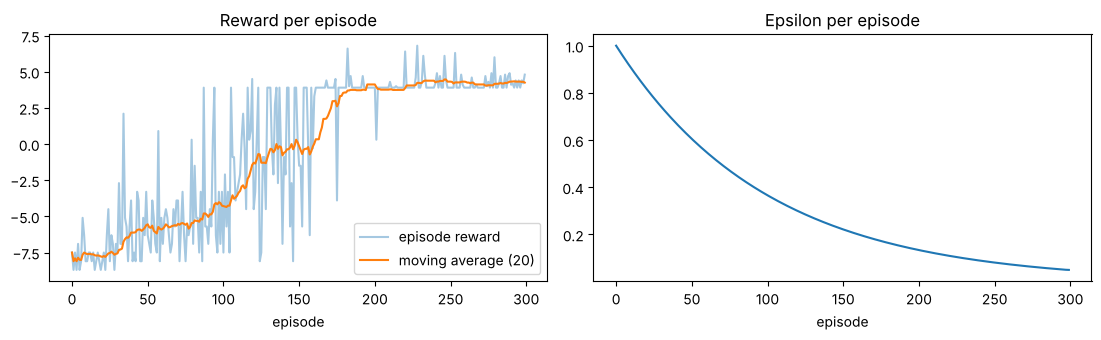

In [31]:
window = 20
moving_avg = []

for i in range(len(rewards_per_episode)):
    start = max(0, i - window + 1)
    chunk = rewards_per_episode[start:i + 1]
    moving_avg.append(sum(chunk) / len(chunk))

print("average reward of the first 20 episodes :", round(sum(rewards_per_episode[:20]) / 20, 2))
print("average reward of the last 20 episodes :", round(sum(rewards_per_episode[-20:]) / 20, 2))
print("average reward of the random bird (Step 1b) :", round(sum(random_rewards) / len(random_rewards), 2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

axes[0].plot(rewards_per_episode, alpha=0.4, label="episode reward")
axes[0].plot(moving_avg, label="moving average (20)")
axes[0].set_title("Reward per episode")
axes[0].set_xlabel("episode")
axes[0].legend()

axes[1].plot(epsilon_per_episode)
axes[1].set_title("Epsilon per episode")
axes[1].set_xlabel("episode")

plt.tight_layout()
plt.show()

## Step 11: Testing the saved model

Testing uses the same environment, but with three changes:

* **Load the saved weights** into the policy network with `load_state_dict(torch.load(...))`. The target network, the memory and the optimizer are not needed, since nothing is learned.
* **`policy_dqn.eval()`** puts the network in evaluation mode. This particular network has no layers that behave differently in training, but it is the correct habit and it costs nothing.
* **No epsilon.** The bird always takes the action with the highest Q value. Exploration was for learning, and here I want to see what the bird has really learned, just like the pure greedy test in Blackjack.

Setting `watch_game = True` opens the game window so I can see the bird fly. It is quicker to leave it `False` when I only want the rewards.

In [32]:
watch_game = False          # change to True to open the game window and watch

test_env = gym.make(env_id, render_mode="human" if watch_game else None, use_lidar=False)

test_dqn = DQN(num_states, num_actions, hidden_dim).to(device)
test_dqn.load_state_dict(torch.load(MODEL_FILE, map_location=device))
test_dqn.eval()

test_rewards = []

for episode in range(5):

    terminated = False
    truncated = False
    episode_reward = 0

    curr_state, info = test_env.reset()
    curr_state = torch.tensor(curr_state, dtype=torch.float32, device=device)

    while not (terminated or truncated) and episode_reward < reward_threshold:

        # no epsilon here: always the action with the highest Q value
        with torch.no_grad():
            action = test_dqn(curr_state.unsqueeze(dim=0)).squeeze().argmax()

        next_state, reward, terminated, truncated, info = test_env.step(action.item())
        episode_reward = episode_reward + reward
        curr_state = torch.tensor(next_state, dtype=torch.float32, device=device)

    test_rewards.append(episode_reward)
    print(f"test episode {episode + 1}: reward = {episode_reward:.1f}")

test_env.close()

print("\naverage test reward of this short run :", round(sum(test_rewards) / len(test_rewards), 2))
print("average reward of the random bird :", round(sum(random_rewards) / len(random_rewards), 2))

test episode 1: reward = 3.9
test episode 2: reward = 3.9
test episode 3: reward = 3.9
test episode 4: reward = 3.9
test episode 5: reward = 3.9

average test reward of this short run : 3.9
average reward of the random bird : -7.65


After 300 episodes the bird scores about +4 in testing, far above the random bird at about -7.5. A reward of about +4 means the bird survived roughly 50 frames and then crashed (+0.1 per frame, then -1), most likely at the first pipe. It has learned to stay away from the top of the screen and to survive until the first pipe. The next job is learning to aim for the gap, which takes thousands of episodes (Step 12).

Two things in this output are worth understanding:

* **The test rewards are the same or very close to each other.** Testing uses no epsilon, so there is no randomness left in the choices. The same network makes the same choices, and every game starts the same way until the first pipe.
* **Testing usually looks better than training.** The training rewards still include the 5% random actions from `epsilon_min`, while the test bird is fully greedy.

## Step 12: Training for real from the terminal

A bird that flies well needs thousands of episodes, which is too long for a notebook. For that the project files are better: the run can be stopped and restarted from the terminal, the best model is saved to disk automatically, and the game window can open on its own for testing. The notebook is where I learn and check ideas. The files are where I train.

**Open the project folder in VS Code**, make sure the interpreter is my `pytorch` environment, open the built in terminal in the project folder, and run:

```
python agent.py flappybirdv0 --train      # training mode, no window, runs until Ctrl + C or the reward threshold
python agent.py flappybirdv0              # testing mode, loads the best saved model and opens the game window
```

| What | Where |
|---|---|
| best model so far | `runs/flappybirdv0.pt` |
| log of every new best 50 episode average | `runs/flappybirdv0.log` |
| stop training | `Ctrl + C` in the terminal |

The model is saved whenever the average reward of the last 50 episodes is a new best, so stopping with `Ctrl + C` never loses the best model.

### What my real run looked like

I trained for about 13,940 episodes. The first few hundred episodes were close to random, and then the average reward climbed as epsilon fell to its floor of 0.05 around episode 300. Single training games mostly scored between +4 and +9, and the best 50 episode average was **15.28 at episode 10,200**.

The training numbers look modest because they still include the 5% random actions from `epsilon_min`, and one badly timed random flap can end a game. Testing has no random actions, and the same saved model played these six games:

| Test game | Reward |
|---|---|
| 1 | 1000 (reward cap reached) |
| 2 | 404.9 |
| 3 | 613.3 |
| 4 | 11.3 |
| 5 | 1000 (reward cap reached) |
| 6 | 852.9 |

Every pipe is worth about 5 reward once the frames in between are counted, so 1000 is roughly 200 pipes. Two games were stopped by the `reward_threshold` while the bird was still flying. One game scored only 11.3, which is about 2 pipes. Deep Q learning is not perfectly steady, so a weak game now and then is normal.

### What I tried along the way

| Setup | What I saw |
|---|---|
| lidar state (180 numbers), one update per episode, about 11,000 episodes | average reward about +0.8, no pipe passed |
| lidar state, one update per step, about 14,500 episodes | average reward about +2, no pipe passed |
| 12 numbers, one update per step, about 13,900 episodes | best 50 episode average 15.28, test games up to the 1000 reward cap |

The 12 number state made the biggest difference. The choice of saving the model by its 50 episode average, and not by one single best game, also matters, because one lucky game can come from a weak network.

## What I take away

* A **Q table** only works when the same state comes back many times. With 12 continuous numbers it never does, so a **neural network** estimates `Q(state, action)` instead.
* **Epsilon greedy with decay** starts at pure exploration, because an untrained network cannot be trusted, and shifts to exploitation slowly.
* **Experience replay** stores every step and trains on random mini batches. This breaks the similarity between consecutive frames and lets each experience be used many times.
* The **target** is `reward + gamma * max Q(next_state)` and just `reward` when the game ended. The network is trained to move its prediction towards that target with an MSE loss.
* The **target network** is a frozen snapshot of the policy network, refreshed every 1000 updates, so the target does not move every time the network changes.
* `zip(*batch)`, `torch.stack`, `max(dim=1)[0]` and `gather` are only tools to run the same calculation on 32 experiences at once.
* **How often the network learns** matters. Updating on every step gave a clearly better bird than updating once per episode, because the network sees far more updates from the same games.
* The **state and the reward** the game gives matter a lot. The same network and similar settings failed with the 180 lidar numbers and worked with the 12 simple ones.